# TP2 — Entraînement et évaluation d'un modèle YOLO
M1 MIAS · Computer Vision et labellisation d'imagerie médicale

**Groupe : Robin FOEX & Alexis ROBIN**

Dataset du TP1 (300 images, 4 classes : `green_apple`, `Banana`, `Orange`, `red_apple`), split 210 / 45 / 45. Modèle : `yolo26n` pré-entraîné (fine-tuning).
Les trois scripts du sujet (`train.py`, `evaluate.py`, `predict.py`) sont dans ce dossier ; ce notebook les lance et analyse leurs sorties.

## Partie A — Vérifier l'environnement

In [3]:
import subprocess, sys, csv
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd()
D = ROOT / "dataset"
for s in ("train", "val", "test"):
    print(s, len(list((D/"images"/s).glob("*.jpg"))), "images,", len(list((D/"labels"/s).glob("*.txt"))), "labels")
print((D / "data.yaml").read_text())

def run(script):
    r = subprocess.run([sys.executable, script], cwd=ROOT, capture_output=True, text=True)
    print("\n".join((r.stdout + r.stderr).replace("\r", "\n").splitlines()[-25:]))
    assert r.returncode == 0, script

train 210 images, 210 labels
val 45 images, 45 labels
test 45 images, 45 labels
train: images/train
val: images/val
test: images/test
names:
  0: green_apple
  1: Banana
  2: Orange
  3: red_apple



## Partie B — Fine-tuning (`train.py`) avec early stopping
Ajouts par rapport au sujet : `epochs=30` (au lieu de 20) et **`patience=5`**. L'early stopping d'Ultralytics surveille la métrique de validation (fitness = 0,1·mAP50 + 0,9·mAP50-95) : si elle ne progresse pas pendant 5 époques, l'entraînement s'arrête, et `best.pt` garde les poids de la meilleure époque. Cela limite le sur-apprentissage (loss d'entraînement qui baisse alors que la validation stagne ou se dégrade).

In [4]:
# Entraînement lancé en direct : on n'affiche que les lignes de suivi par époque (EPOCH ...) et l'early stopping
proc = subprocess.Popen([sys.executable, "-u", "train.py"], cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
tail = []
for line in proc.stdout:
    tail = (tail + [line])[-30:]
    for part in line.replace("\r", "\n").splitlines():
        if part.startswith("EPOCH") or "EarlyStopping" in part or "Stopping training" in part:
            print(part, flush=True)
assert proc.wait() == 0, "".join(tail)

EPOCH 1/30 | 79s (total 1.3 min, reste ~38.1 min max) | mAP50 0.368 | mAP50-95 0.296 | meilleur fitness 0.296
EPOCH 2/30 | 81s (total 2.7 min, reste ~37.2 min max) | mAP50 0.501 | mAP50-95 0.367 | meilleur fitness 0.367
EPOCH 3/30 | 32s (total 3.2 min, reste ~28.7 min max) | mAP50 0.594 | mAP50-95 0.467 | meilleur fitness 0.467
EPOCH 4/30 | 33s (total 3.7 min, reste ~24.3 min max) | mAP50 0.607 | mAP50-95 0.417 | meilleur fitness 0.467
EPOCH 5/30 | 37s (total 4.4 min, reste ~21.8 min max) | mAP50 0.592 | mAP50-95 0.444 | meilleur fitness 0.467
EPOCH 6/30 | 40s (total 5.0 min, reste ~20.1 min max) | mAP50 0.620 | mAP50-95 0.469 | meilleur fitness 0.469
EPOCH 7/30 | 70s (total 6.2 min, reste ~20.3 min max) | mAP50 0.678 | mAP50-95 0.525 | meilleur fitness 0.525
EPOCH 8/30 | 47s (total 7.0 min, reste ~19.2 min max) | mAP50 0.742 | mAP50-95 0.595 | meilleur fitness 0.595
EPOCH 9/30 | 46s (total 7.7 min, reste ~18.0 min max) | mAP50 0.764 | mAP50-95 0.598 | meilleur fitness 0.598
EPOCH 10/3

30 époques effectuées sur 30 ; meilleure époque : 30 (mAP50-95 val = 0.719)


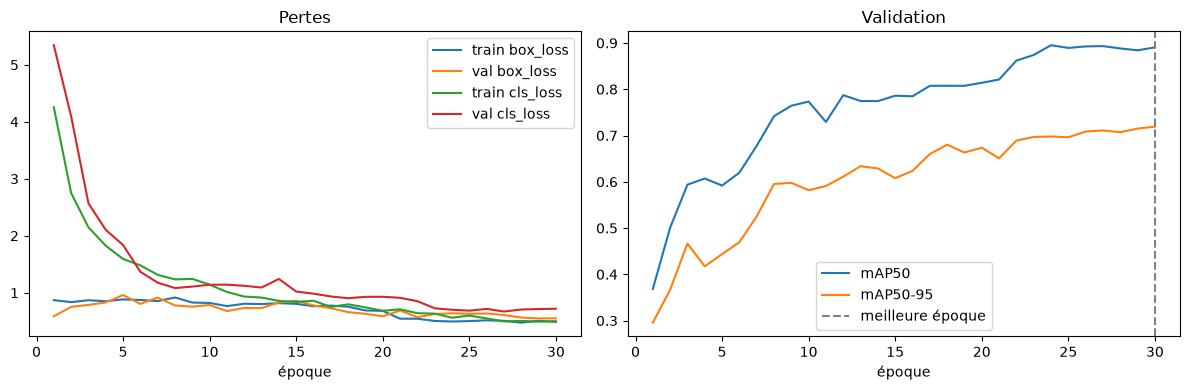

In [5]:
rows = list(csv.DictReader(open(ROOT/"runs/fruits_detection/results.csv")))
rows = [{k.strip(): float(v) for k, v in r.items()} for r in rows]
ep = [r["epoch"] for r in rows]
best = max(rows, key=lambda r: 0.1*r["metrics/mAP50(B)"] + 0.9*r["metrics/mAP50-95(B)"])
print(f"{len(rows)} époques effectuées sur 30 ; meilleure époque : {int(best['epoch'])} (mAP50-95 val = {best['metrics/mAP50-95(B)']:.3f})")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, [r["train/box_loss"] for r in rows], label="train box_loss")
ax[0].plot(ep, [r["val/box_loss"] for r in rows], label="val box_loss")
ax[0].plot(ep, [r["train/cls_loss"] for r in rows], label="train cls_loss")
ax[0].plot(ep, [r["val/cls_loss"] for r in rows], label="val cls_loss"); ax[0].set_title("Pertes"); ax[0].legend()
ax[1].plot(ep, [r["metrics/mAP50(B)"] for r in rows], label="mAP50")
ax[1].plot(ep, [r["metrics/mAP50-95(B)"] for r in rows], label="mAP50-95")
ax[1].axvline(best["epoch"], ls="--", c="gray", label="meilleure époque"); ax[1].set_title("Validation"); ax[1].legend()
for a in ax: a.set_xlabel("époque")
plt.tight_layout(); plt.show()

## Partie C — Évaluation sur le test (`evaluate.py`)

In [8]:
run("evaluate.py")

Ultralytics 8.4.215 🚀 Python-3.14.2 torch-2.15.0 CPU (Apple M3)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2099.6±1334.7 MB/s, size: 73.5 KB)

val: Scanning /Users/robinf/imagerie/TP2_computervision/TP2/dataset/labels/test.cache... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 11.8Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 33% ━━━━──────── 1/3 1.4s/it 0.4s<2.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 66% ━━━━━━━━──── 2/3 1.1it/s 0.9s<0.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.3it/s 1.3s
                   all         45         67      0.921      0.885      0.967      0.891
           green_apple          2          3      0.903          1      0.995      0.907
                Banana         19       

In [9]:
import numpy as np
from ultralytics import YOLO
model = YOLO(str(ROOT/"runs/fruits_detection/weights/best.pt"))
m = model.val(data=str(D/"data.yaml"), split="test", imgsz=640, plots=False, verbose=False)
p, r = m.box.mp, m.box.mr
print(f"Precision {p:.3f} | Recall {r:.3f} | F1 {2*p*r/(p+r):.3f} | mAP@50 {m.box.map50:.3f} | mAP@50-95 {m.box.map:.3f}")
names = model.names
for i, n in names.items():
    print(f"{n:12s} P {m.box.p[i]:.3f}  R {m.box.r[i]:.3f}  AP50 {m.box.ap50[i]:.3f}  AP50-95 {m.box.ap[i]:.3f}")

Ultralytics 8.4.215 🚀 Python-3.14.2 torch-2.15.0 CPU (Apple M3)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2295.2±1319.8 MB/s, size: 62.1 KB)
val: Scanning /Users/robinf/imagerie/TP2_computervision/TP2/dataset/labels/test.cache... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 3.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.4it/s 1.3s0.8s
                   all         45         67      0.921      0.885      0.967      0.891
Speed: 0.6ms preprocess, 24.0ms inference, 0.0ms loss, 0.1ms postprocess per image
Precision 0.921 | Recall 0.885 | F1 0.903 | mAP@50 0.967 | mAP@50-95 0.891
green_apple  P 0.903  R 1.000  AP50 0.995  AP50-95 0.907
Banana       P 0.912  R 0.945  AP50 0.978  AP50-95 0.900
Orange       P 0.946  R 0.795  AP50 0.965  AP50-95 0.922
red_apple    P 0.924  R 0.800  AP50 0.931  AP50-95 0.835


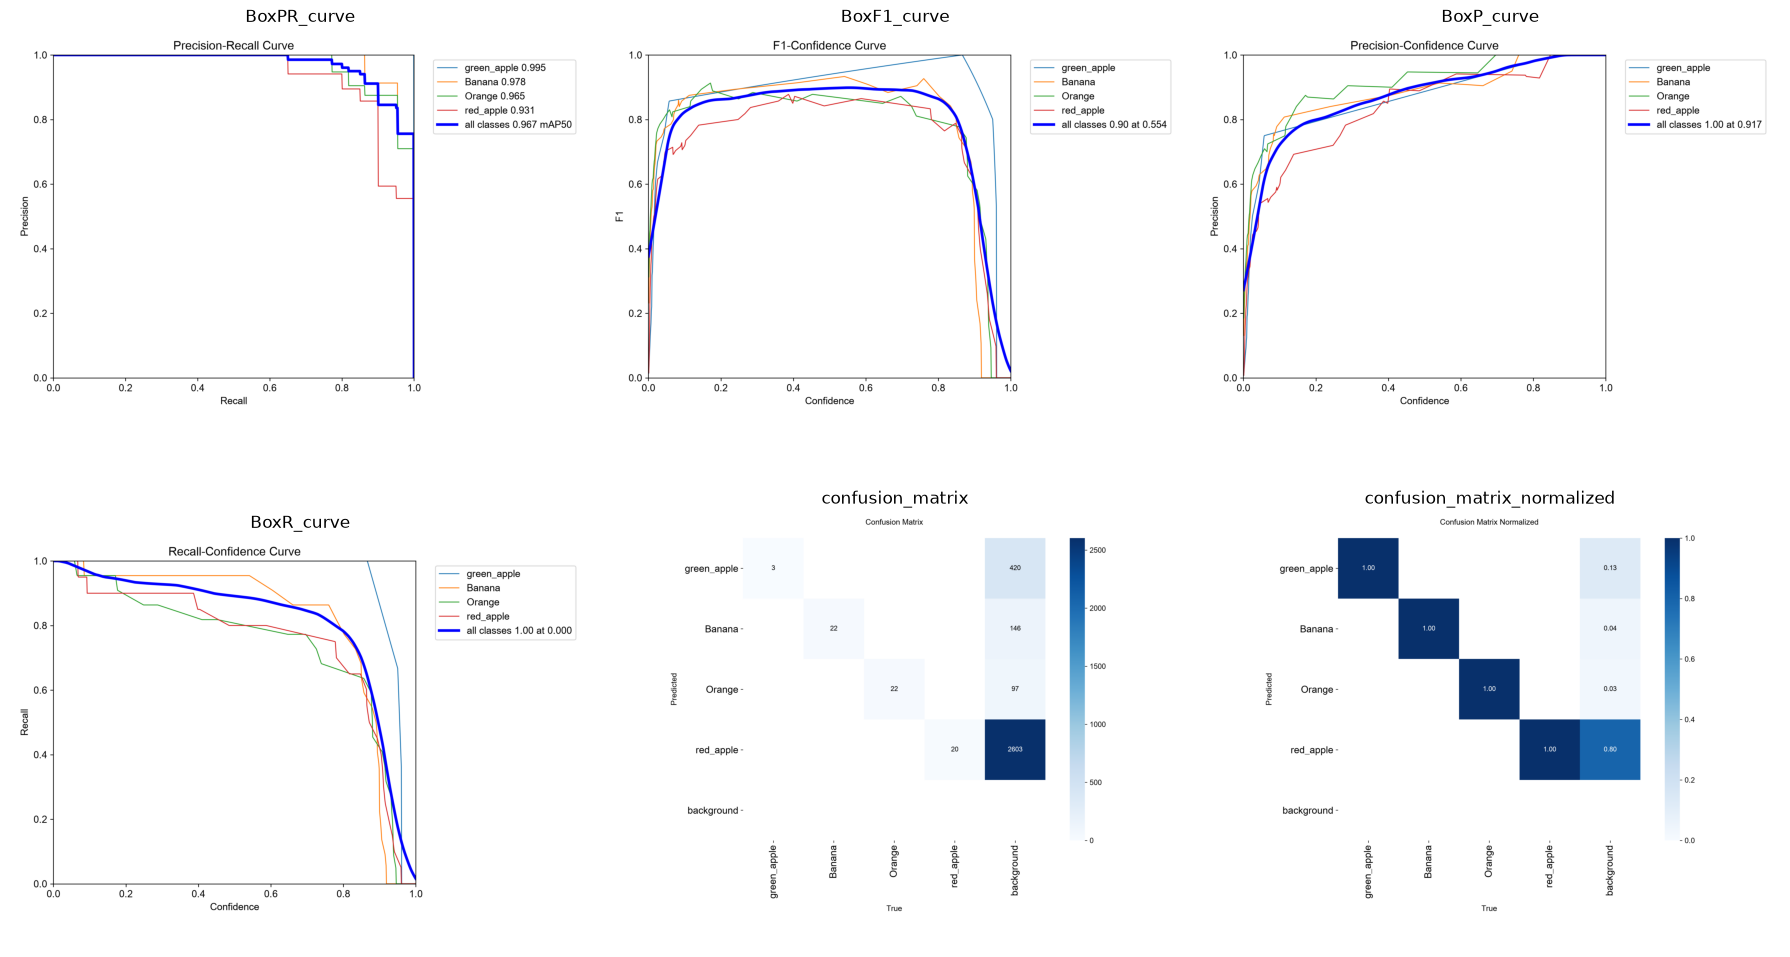

In [10]:
E = ROOT / "evaluation_results/YOLO_Test"
fig, ax = plt.subplots(2, 3, figsize=(18, 11))
for a, f in zip(ax.flat, ["BoxPR_curve", "BoxF1_curve", "BoxP_curve", "BoxR_curve", "confusion_matrix", "confusion_matrix_normalized"]):
    a.imshow(Image.open(E / f"{f}.png")); a.set_title(f); a.axis("off")
plt.tight_layout(); plt.show()

## Partie D — Prédictions (`predict.py`)

In [11]:
run("predict.py")

image 23/45 /Users/robinf/imagerie/TP2_computervision/TP2/dataset/images/test/image237.jpg: 640x640 1 Orange, 30.0ms
image 24/45 /Users/robinf/imagerie/TP2_computervision/TP2/dataset/images/test/image247.jpg: 608x640 1 red_apple, 29.0ms
image 25/45 /Users/robinf/imagerie/TP2_computervision/TP2/dataset/images/test/image264.jpg: 480x640 1 Banana, 23.6ms
image 26/45 /Users/robinf/imagerie/TP2_computervision/TP2/dataset/images/test/image268.jpg: 384x640 1 Banana, 19.6ms
image 27/45 /Users/robinf/imagerie/TP2_computervision/TP2/dataset/images/test/image271.jpg: 480x640 1 Banana, 1 red_apple, 25.1ms
image 28/45 /Users/robinf/imagerie/TP2_computervision/TP2/dataset/images/test/image276.jpg: 640x640 2 Bananas, 31.8ms
image 29/45 /Users/robinf/imagerie/TP2_computervision/TP2/dataset/images/test/image280.jpg: 480x640 1 Banana, 1 Orange, 1 red_apple, 26.5ms
image 30/45 /Users/robinf/imagerie/TP2_computervision/TP2/dataset/images/test/image289.jpg: 640x640 1 Orange, 32.3ms
image 31/45 /Users/robin

45 images annotées


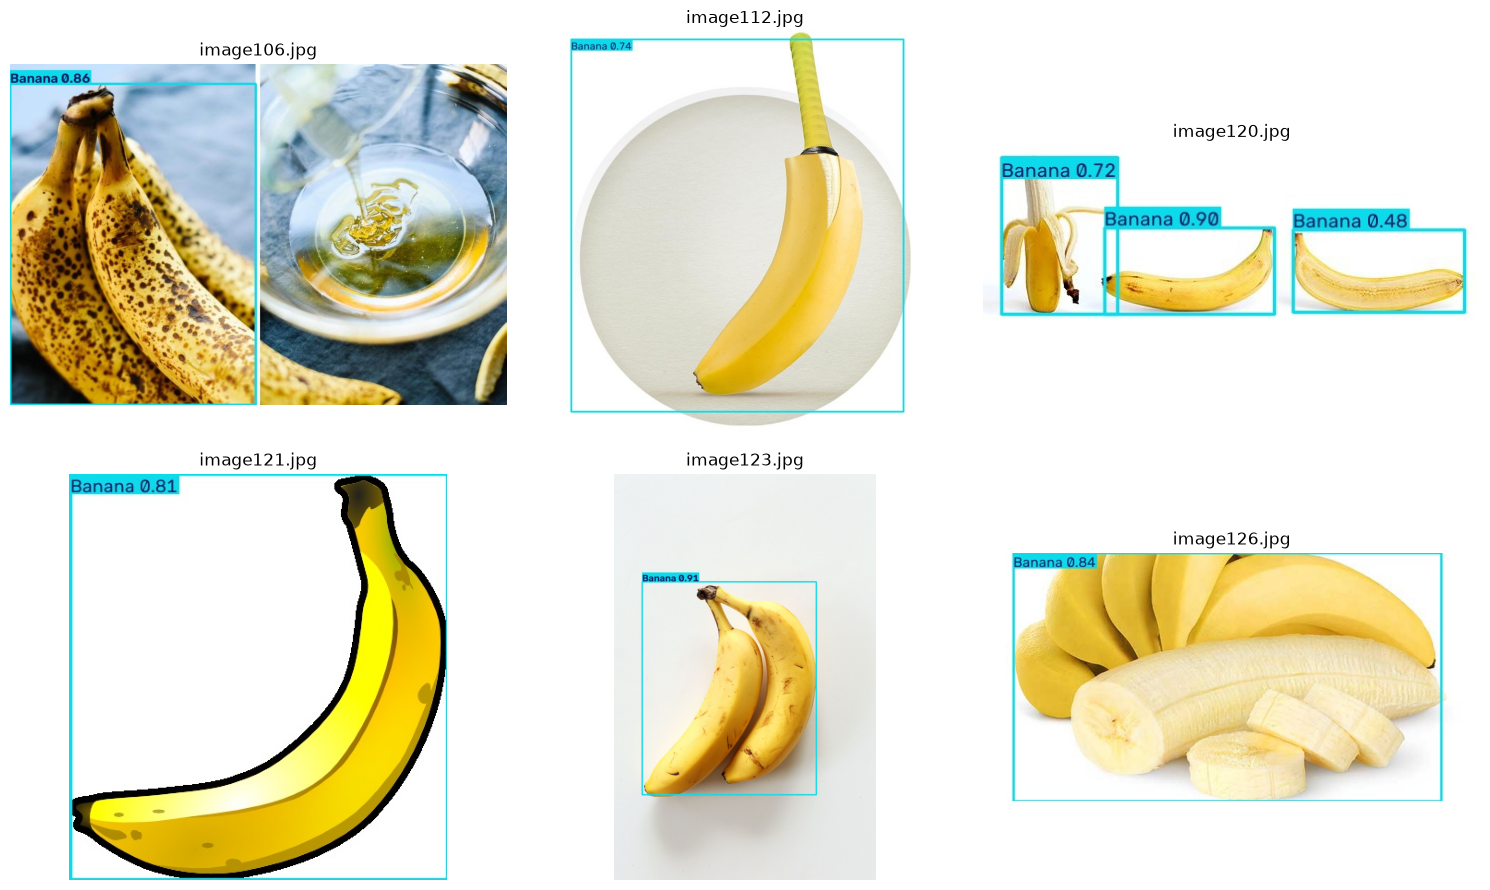

In [12]:
P = sorted((ROOT/"predictions/YOLO_Predictions").glob("*.jpg"))
print(len(P), "images annotées")
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, p in zip(ax.flat, P[:6]): a.imshow(Image.open(p)); a.set_title(p.name); a.axis("off")
plt.tight_layout(); plt.show()

## Partie E — Analyse des erreurs
On compare, image par image, les prédictions (conf ≥ 0,25) aux boîtes de vérité terrain du test (appariement par IoU ≥ 0,5) :
- **correct** : boîte appariée, bonne classe ;
- **mauvaise classe** : boîte appariée, classe différente ;
- **faux positif** : détection sans vérité terrain ;
- **faux négatif** : fruit non détecté.

In [13]:
def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    i = ix * iy
    return i / ((a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - i + 1e-9)

def gt_boxes(stem, W, H):
    out = []
    for l in (D/"labels/test"/f"{stem}.txt").read_text().splitlines():
        if l.strip():
            c, x, y, w, h = l.split(); x, y, w, h = float(x)*W, float(y)*H, float(w)*W, float(h)*H
            out.append((int(c), (x-w/2, y-h/2, x+w/2, y+h/2)))
    return out

from collections import Counter, defaultdict
tot, ex = Counter(), defaultdict(list)
for res in model.predict(source=str(D/"images/test"), conf=0.25, verbose=False):
    stem = Path(res.path).stem; H, W = res.orig_shape
    gts = gt_boxes(stem, W, H)
    preds = sorted(zip(res.boxes.cls.int().tolist(), res.boxes.conf.tolist(), res.boxes.xyxy.tolist()), key=lambda t: -t[1])
    used = set()
    for c, cf, bb in preds:
        best_i, best_v = None, 0.5
        for i, (gc, gb) in enumerate(gts):
            if i not in used and iou(bb, gb) >= best_v: best_i, best_v = i, iou(bb, gb)
        if best_i is None: k = "faux positif"
        else:
            used.add(best_i); k = "correct" if gts[best_i][0] == c else "mauvaise classe"
        tot[k] += 1; ex[k].append(stem)
    for i in range(len(gts)):
        if i not in used: tot["faux négatif"] += 1; ex["faux négatif"].append(stem)
print(dict(tot))
for k in ("mauvaise classe", "faux positif", "faux négatif"): print(k, ":", sorted(set(ex[k])))

{'correct': 62, 'faux positif': 8, 'faux négatif': 5}
mauvaise classe : []
faux positif : ['image112', 'image150', 'image159', 'image17', 'image230', 'image271', 'image3']
faux négatif : ['image112', 'image159', 'image230', 'image3', 'image44']


### Lecture des résultats *(à compléter pour la soutenance après relecture des images listées ci-dessus)*
- **Quantité de données** : seulement 300 images, dont 19 boîtes `green_apple` (3 au test) : les métriques de cette classe sont très bruitées.
- **Qualité des annotations** : les boîtes proviennent de CVAT, une boîte trop large ou décalée dégrade surtout le mAP@50-95.
- **Diversité** : beaucoup d'images à fruit unique ; les scènes à plusieurs fruits ou aux fruits superposés sont les plus à risque.
- **Early stopping** : voir le nombre d'époques effectuées en partie B.

## Prolongement avec YOLO11n

YOLO11n utilise le même jeu de données que notre YOLO26n, à 640 px avec
des lots de 8 et une patience de cinq époques sur la validation. Les deux
modèles ont ensuite été réévalués sur les mêmes 45 images de test, avec
les mêmes annotations et la même version d'Ultralytics.

L'accuracy de classe porte sur les boîtes appariées à IoU 0,50. Le F1 micro
inclut aussi les faux positifs et les faux négatifs. Les matrices de cette
comparaison sont calculées au seuil de confiance de 0,25.


In [ ]:
import json
from pathlib import Path

comparaison = Path.cwd().parent / "comparaison"
scores = json.loads((comparaison / "resultats.json").read_text())["tests_origine"]
matrices = json.loads((comparaison / "confusions.json").read_text())
print(f"{'Modèle':9s} {'mAP@50':>9s} {'mAP@50–95':>11s} {'Acc. classe':>13s} {'F1 micro':>10s}")
for nom, cle in (("YOLO26n", "robin"), ("YOLO11n", "robin_yolo11")):
    ap = scores[cle]
    mesure = matrices[cle]["test_origine"]
    print(f"{nom:9s} {ap['map50']:9.1%} {ap['map50_95']:11.1%} "
          f"{mesure['accuracy_classe_boites_appariees']:13.1%} {mesure['f1_micro']:10.1%}")


Modèle       mAP@50   mAP@50–95   Acc. classe   F1 micro
YOLO26n       96.7%       88.7%        100.0%      91.2%
YOLO11n       95.5%       86.0%         96.8%      80.5%


## Livrable

In [14]:
import zipfile
out = ROOT / "TP2_Groupe_FOEX_ROBIN_YOLO.zip"
items = [D/"data.yaml", ROOT/"train.py", ROOT/"evaluate.py", ROOT/"predict.py", ROOT/"runs/fruits_detection/weights/best.pt",
         ROOT/"runs/fruits_detection/results.csv", ROOT/"runs/fruits_detection/results.png"]
items += [p for p in (ROOT/"evaluation_results").rglob("*.png")] + [p for p in (ROOT/"predictions").rglob("*.jpg")]
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for p in items:
        if p.exists(): z.write(p, p.relative_to(ROOT).as_posix())
print(out, len(zipfile.ZipFile(out).namelist()), "fichiers")

/Users/robinf/imagerie/TP2_computervision/TP2/TP2_Groupe_FOEX_ROBIN_YOLO.zip 58 fichiers
